# How a Fourier Neural Operator learns a PDE: Burgers' equation

This notebook builds a tiny **Fourier Neural Operator (FNO)**, the model from Li et al. 2021, *Fourier Neural
Operator for Parametric Partial Differential Equations* ([arXiv:2010.08895](https://arxiv.org/abs/2010.08895)).
It trains the model on the paper's 1D benchmark, viscous Burgers' equation, and lets you look **inside** it: every
tensor, in physical space and in Fourier space, at every point of training.

The GNS notebook ([`gnn_explained.ipynb`](../../../05-graph-neural-networks/gnn/notebooks/gnn_explained.ipynb))
learned a **time step**: state now → acceleration now. The FNO learns something bigger, the **solution operator**:
a whole input function → a whole output function. "Learning the function" here means learning the map between
functions, not one solution.

**Plan**

1. The ground truth: Burgers' equation and the operator $G: u_0 \mapsto u(\cdot, 1)$.
2. What goes in and what comes out: the input matrix, the target, the batch.
3. The architecture with every shape: lift **P** → 4 × Fourier layer → project **Q**.
4. One forward pass, tensor by tensor, with a worked numeric example for each step:
   lifting, **FFT**, **mode truncation**, **spectral weights R**, **inverse FFT**, pointwise **W**, activation,
   projection.
5. The loss (relative $L^2$) and where its gradient comes from.
6. Training, with a weight snapshot every 100 steps.
7. An **interactive explorer** with sliders for *training step*, *test sample* and *layer*.
8. What it learned: predictions, **zero-shot super-resolution** (train on 32 points, run on 256), and the spectrum.
9. Your question: **does the FNO have anything to do with the adjoint method?**

Sizes are small on purpose: $N = 32$ grid points, $d = 8$ channels, $k_{max} = 8$ Fourier modes, so every matrix
fits on screen. The paper uses $d = 64$, $k_{max} = 16$ and up to 8192 grid points.

In [1]:
import sys
sys.path.insert(0, "..")

import time
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from src.physics import BurgersParams, grid, solve, make_dataset
from src.model import FNOConfig, init_params, make_input, spectral_conv, apply_with_trace, apply
from src.training import relative_l2, batch_loss, train, evaluate
from src import visualize as viz

plt.rcParams["figure.dpi"] = 100

## 1. The ground truth: Burgers' equation and the operator to learn

On the periodic interval $x \in [0, 1)$ the viscous Burgers' equation is

$$
\partial_t u + \partial_x\!\big(\tfrac12 u^2\big) = \nu\, \partial_{xx} u, \qquad \nu = 0.02 .
$$

(The paper uses $\nu = 0.1$. On this domain that damps the solution to about 2% of its initial size by $t = 1$,
and what is left is almost pure linear diffusion. With $\nu = 0.02$ the nonlinear advection term really matters,
and the solution is still smooth enough for 32 grid points.)

The advection term steepens the wave (the peaks move faster than the troughs), the viscosity smooths it. Paper
Sec. 5.1 learns the map from the initial condition to the solution at $t = 1$:

$$
G:\; u_0(x) \;\longmapsto\; u(x, 1).
$$

Initial conditions come from the paper's Gaussian random field, $u_0 \sim \mathcal N\big(0,\, 625(-\Delta + 25 I)^{-2}\big)$.
Each sample is a different smooth function, so each sample is a different **instance** of the PDE. A PINN would have
to be retrained for every one of them; the FNO is trained once for all of them.

The reference solver (`src/physics.py`, pseudo-spectral + RK4) runs on 256 points. The FNO only ever sees every
8th point: $N = 32$. Keeping the fine solutions lets us test the FNO at higher resolution later (section 8).

solved 1200 Burgers problems at 256 points in 1.1 s


train: (1000, 32) -> (1000, 32)    test: (200, 32) -> (200, 32)


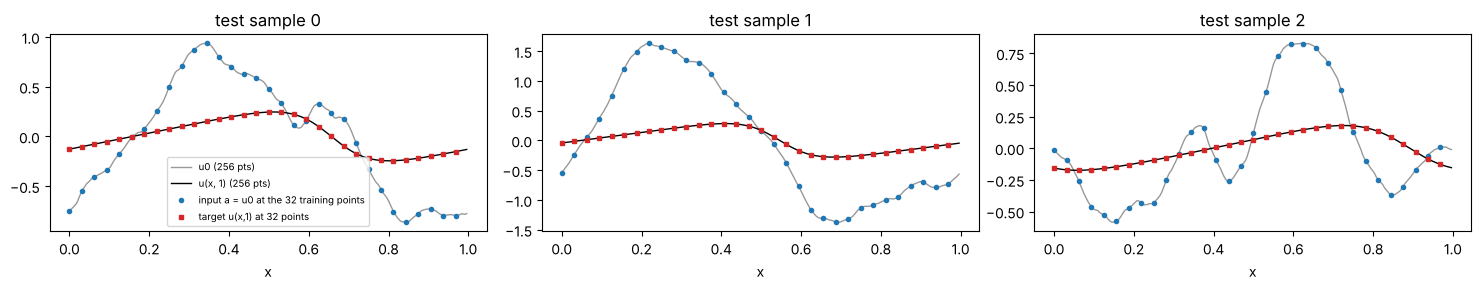

In [2]:
phys = BurgersParams()          # nu = 0.02, t = 1, 256 reference points, dt = 1e-3
t0 = time.time()
data = make_dataset(jax.random.PRNGKey(0), n_samples=1200, params=phys)
print(f"solved 1200 Burgers problems at {phys.n_fine} points in {time.time() - t0:.1f} s")

N = 32                          # training resolution
s = phys.n_fine // N            # keep every s-th point
x_fine, x = np.asarray(grid(phys.n_fine)), np.asarray(grid(N))
a_train, u_train = data["a"][:1000, ::s], data["u"][:1000, ::s]
a_test, u_test = data["a"][1000:, ::s], data["u"][1000:, ::s]
print("train:", a_train.shape, "->", u_train.shape, "   test:", a_test.shape, "->", u_test.shape)

fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, i in zip(axes, [0, 1, 2]):
    ax.plot(x_fine, data["a"][1000 + i], color="0.6", lw=1, label="u0 (256 pts)")
    ax.plot(x_fine, data["u"][1000 + i], color="k", lw=1, label="u(x, 1) (256 pts)")
    ax.plot(x, a_test[i], "o", ms=3, color="tab:blue", label="input a = u0 at the 32 training points")
    ax.plot(x, u_test[i], "s", ms=3, color="tab:red", label="target u(x,1) at 32 points")
    ax.set_title(f"test sample {i}"); ax.set_xlabel("x")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

Each panel is **one training example for an operator**: a whole function in (grey / blue dots), a whole function
out (black / red squares). Over one time unit the viscosity has damped the wiggles and the advection has shifted and
steepened the wave.

## 2. What goes in, what comes out

For one sample the FNO receives an **$N \times 2$ input matrix**. Row $j$ is grid point $x_j = j/N$, and its two
columns are

* $a(x_j) = u_0(x_j)$, the value of the input function there, and
* $x_j$ itself. The paper appends the coordinate so the network can tell grid points apart (code: `get_grid`).

The output is one number per grid point, the prediction of $u(x_j, 1)$: an **$N$-vector** (written $N \times 1$).
A batch just stacks samples: inputs $(B, N, 2)$, outputs $(B, N)$. The same weights run on every sample.

Because inputs and outputs are **functions sampled on a grid**, $N$ is not part of the model. Section 8 feeds the
same trained model $N = 256$ rows instead of 32.

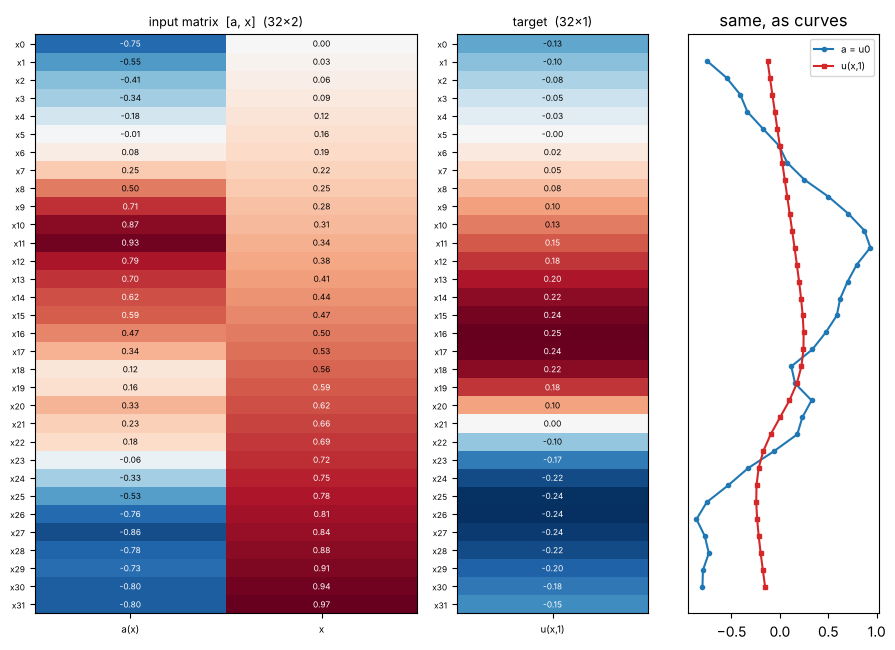

In [3]:
i = 0
X_in = np.asarray(make_input(a_test[i]))
fig, axes = plt.subplots(1, 3, figsize=(9, 6.6), gridspec_kw=dict(width_ratios=[2, 1, 1]))
viz.matrix(axes[0], X_in, viz.grid_labels(N), ["a(x)", "x"], "input matrix  [a, x]  (32×2)")
viz.matrix(axes[1], np.asarray(u_test[i])[:, None], viz.grid_labels(N), ["u(x,1)"], "target  (32×1)")
axes[2].plot(a_test[i], np.arange(N), "o-", ms=3, label="a = u0"); axes[2].plot(u_test[i], np.arange(N), "s-", ms=3, color="tab:red", label="u(x,1)")
axes[2].invert_yaxis(); axes[2].set_yticks([]); axes[2].legend(fontsize=7); axes[2].set_title("same, as curves")
plt.tight_layout(); plt.show()

## 3. The architecture, with every shape

Paper Sec. 4 (Fig. 2). Every arrow is either **pointwise** (the same small matrix at every grid point) or acts on
**Fourier modes**. That is the whole trick.

| stage | formula | shape for one sample |
|---|---|---|
| input | $[a(x_j), x_j]$ | $32 \times 2$ |
| **lift P** | $v_0 = [a, x]\,P + b_P$ | $32 \times 8$ |
| **FFT** | $\hat v_k = \frac1N \sum_j v(x_j)\, e^{-2\pi i k j/N}$, for $k = 0..16$ | $17 \times 8$ complex |
| **truncate** | keep $k < k_{max} = 8$ | $8 \times 8$ complex |
| **spectral weights R** | $(R\hat v)_k = \hat v_k\, R[k]$, one $8\times 8$ complex matrix per mode | $8 \times 8$ complex |
| **inverse FFT** | zero-pad modes 8..16, back to the grid: $\mathcal K v$ | $32 \times 8$ |
| **pointwise W** | $W v + b$, the same $8\times8$ matrix at every $x_j$ | $32 \times 8$ |
| **activation** | $v_{t+1} = \text{GELU}(\mathcal K v + W v + b)$ | $32 \times 8$ |
| | repeat for 4 Fourier layers (own $R, W, b$ each; no GELU after the last) | |
| **project Q** | $u = \text{GELU}(v_4 Q_1 + c_1)\, Q_2 + c_2$ | $32 \times 32 \to 32 \times 1$ |

**Why the FFT?** A neural-operator layer is $v \mapsto \sigma\big(W v + \mathcal K v\big)$ with a kernel integral
$(\mathcal K v)(x) = \int \kappa(x - y)\, v(y)\, dy$ (paper Eq. 3). An integral of $\kappa(x-y)$ against $v$ is a
**convolution**, and the convolution theorem turns it into a product of Fourier coefficients:

$$
\widehat{(\kappa * v)}_k = \hat\kappa_k \cdot \hat v_k .
$$

So instead of learning $\kappa(x)$ on the grid, FNO learns $\hat\kappa_k$ directly, for the first $k_{max}$
frequencies only, and lets it be a $d \times d$ matrix so it can also mix channels: that is $R[k]$ (paper Eq. 4).
A dense kernel integral costs $O(N^2)$; this costs $O(N \log N)$ and every output point sees every input point.

Compare with GNS: a message-passing step only sees neighbours within radius $R$, so information moves one hop per
step. One Fourier layer is **global**.

In [4]:
cfg = FNOConfig(width=8, modes=8, layers=4, proj_hidden=32)
params0 = init_params(jax.random.PRNGKey(1), cfg)

n_params = sum(int(np.prod(p.shape)) for p in jax.tree_util.tree_leaves(params0))
print(f"parameters: {n_params}  (P: {2*8+8}, each Fourier layer: R {2*8*8*8} (re+im) + W {8*8} + b 8, Q: {8*32+32+32+1})")

tr = apply_with_trace(params0, a_test[0])
for name in tr._fields:
    print(f"{name:12s} {str(tuple(getattr(tr, name).shape)):14s} {getattr(tr, name).dtype}")

parameters: 4729  (P: 24, each Fourier layer: R 1024 (re+im) + W 64 + b 8, Q: 321)


inputs       (32, 2)        float32
lifted       (32, 8)        float32
v_hat        (4, 17, 8)     complex64
v_hat_kept   (4, 8, 8)      complex64
Rv_hat       (4, 8, 8)      complex64
spectral     (4, 32, 8)     float32
local        (4, 32, 8)     float32
pre_act      (4, 32, 8)     float32
v            (4, 32, 8)     float32
proj_hidden  (32, 32)       float32
output       (32,)          float32


Most of the parameters are in $R$: $k_{max} \times d \times d$ complex numbers per layer. None of them depends on
$N$. (The trace stacks the 4 layers on the first axis.)

## 4. One forward pass, tensor by tensor

We push test sample 0 through the **untrained** network `params0`. The numbers are random for now; the shapes, the
flow and the arithmetic are the point. After training (section 6) the explorer shows the trained values.

### 4a. Lift P: from 2 numbers per point to 8 channels

$P$ is a $2 \times 8$ matrix plus a bias. The same $P$ is applied to every row, so row $j$ of $v_0$ only depends on
row $j$ of the input. This is a "1×1 convolution": no information moves between grid points yet.

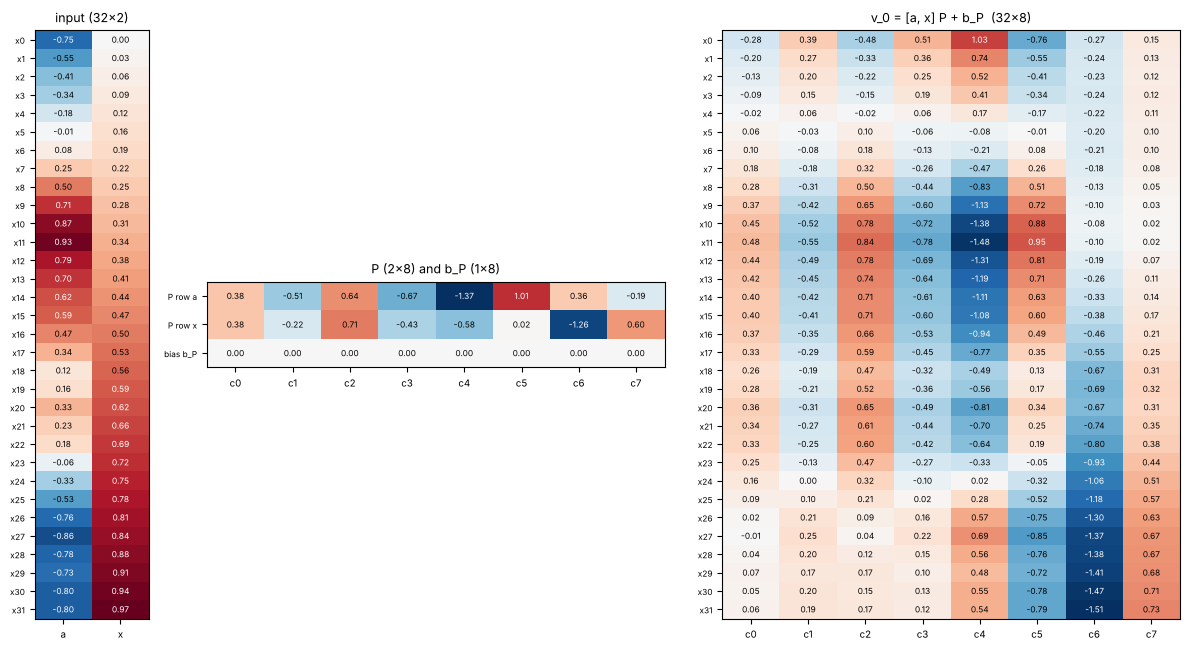

row x5: a = -0.0091, x = 0.1562
v_0[x5] by hand = a·P[0,:] + x·P[1,:] + b_P = [ 0.056 -0.03   0.105 -0.061 -0.078 -0.006 -0.2    0.095]
v_0[x5] from the model                    = [ 0.056 -0.03   0.105 -0.061 -0.078 -0.006 -0.2    0.095]


In [5]:
W_P, b_P = (np.asarray(p) for p in params0["P"])
fig, axes = plt.subplots(1, 3, figsize=(12, 6.6), gridspec_kw=dict(width_ratios=[2, 8, 8]))
viz.matrix(axes[0], tr.inputs, viz.grid_labels(N), ["a", "x"], "input (32×2)")
viz.matrix(axes[1], np.r_[W_P, b_P[None]], ["P row a", "P row x", "bias b_P"], viz.channel_labels(8),
           "P (2×8) and b_P (1×8)")
axes[1].set_aspect(0.5)
viz.matrix(axes[2], tr.lifted, viz.grid_labels(N), viz.channel_labels(8), "v_0 = [a, x] P + b_P  (32×8)")
plt.tight_layout(); plt.show()

j = 5   # worked example: grid point x_5
row = np.asarray(tr.inputs[j])
by_hand = row[0] * W_P[0] + row[1] * W_P[1] + b_P
print(f"row x{j}: a = {row[0]:.4f}, x = {row[1]:.4f}")
print(f"v_0[x{j}] by hand = a·P[0,:] + x·P[1,:] + b_P = {by_hand.round(3)}")
print(f"v_0[x{j}] from the model                    = {np.asarray(tr.lifted[j]).round(3)}")

### 4b. FFT: from 32 grid values to 17 Fourier coefficients, channel by channel

Each of the 8 columns of $v_0$ is a function sampled at 32 points. The real FFT (`rfft`, normalised by $1/N$)
rewrites each column as a sum of waves:

$$
\hat v_k = \frac1N \sum_{j=0}^{N-1} v(x_j)\, e^{-2\pi i k j / N}, \qquad
v(x_j) = \hat v_0 + 2\,\mathrm{Re}\sum_{k=1}^{N/2} \hat v_k\, e^{2\pi i k j/N} \;(\text{the } k = N/2 \text{ term once}).
$$

A real signal of 32 values has $N/2 + 1 = 17$ independent complex coefficients ($k = 0..16$); the negative
frequencies are complex conjugates and carry no new information. $k = 0$ is the mean of the column, $k = 1$ is one
full wave across $[0, 1)$, and so on up to $k = 16$, the fastest wave the grid can show.

Worked example: **channel c0, mode k = 1**, by hand from the 32 numbers in column c0 of $v_0$.

In [6]:
v0 = np.asarray(tr.lifted)
col = v0[:, 0]
terms = col * np.exp(-2j * np.pi * 1 * np.arange(N) / N)
print("first 4 terms v(x_j)·e^{-2πi·1·j/32}:", np.round(terms[:4], 3))
print(f"v̂_1 (channel c0) by hand = (1/32)·sum of all 32 terms = {terms.sum() / N:.4f}")
print(f"v̂_1 (channel c0) from jnp.fft.rfft(norm='forward')   = {complex(tr.v_hat[0][1, 0]):.4f}")
print(f"v̂_0 (channel c0) = mean of the column = {col.mean():.4f}  vs  {complex(tr.v_hat[0][0, 0]).real:.4f}")

first 4 terms v(x_j)·e^{-2πi·1·j/32}: [-0.284+0.j    -0.192+0.038j -0.12 +0.05j  -0.076+0.051j]
v̂_1 (channel c0) by hand = (1/32)·sum of all 32 terms = -0.1269-0.0197j
v̂_1 (channel c0) from jnp.fft.rfft(norm='forward')   = -0.1269-0.0197j
v̂_0 (channel c0) = mean of the column = 0.1827  vs  0.1827


### 4c. Mode truncation: keep only $k < k_{max} = 8$

The heatmap on the left shows $|\hat v_k|$ for all 17 modes and all 8 channels. FNO keeps the cyan box (the 8
lowest frequencies) and **throws the other 9 modes away** (sets them to zero). It is a learned *low-pass* filter.

Two consequences:

* The global path cannot produce frequencies above $k_{max}$. The pointwise path $W$ and the nonlinearity
  (next steps) can, which is how FNO still represents some fine detail.
* The kept modes are the same physical frequencies at any resolution. On a 256-point grid there are 129 modes, but
  modes 0..7 mean exactly the same waves. That is why the weights transfer across resolutions.

Burgers solutions with $\nu = 0.1$ are smooth, so almost all their energy is in the first few modes anyway (right
panel: the training targets, averaged).

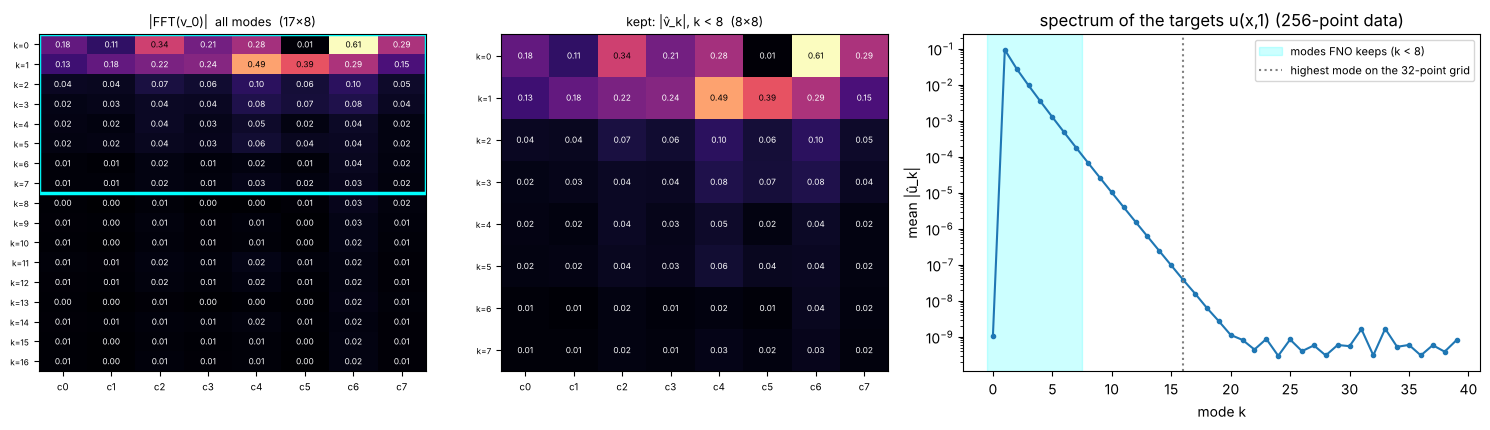

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw=dict(width_ratios=[1.2, 1.2, 1.6]))
vh = np.abs(np.asarray(tr.v_hat[0]))
viz.matrix(axes[0], vh, viz.mode_labels(17), viz.channel_labels(8), "|FFT(v_0)|  all modes  (17×8)", cmap="magma")
from matplotlib.patches import Rectangle
axes[0].add_patch(Rectangle((-0.5, -0.5), 8, cfg.modes, fill=False, ec="cyan", lw=2.5))
viz.matrix(axes[1], np.abs(np.asarray(tr.v_hat_kept[0])), viz.mode_labels(8), viz.channel_labels(8),
           "kept: |v̂_k|, k < 8  (8×8)", cmap="magma")
spec = np.abs(np.fft.rfft(np.asarray(data["u"][:1000]), axis=1, norm="forward")).mean(0)
axes[2].semilogy(spec[:40], "o-", ms=3)
axes[2].axvspan(-0.5, cfg.modes - 0.5, color="cyan", alpha=0.2, label=f"modes FNO keeps (k < {cfg.modes})")
axes[2].axvline(N // 2, color="0.5", ls=":", label="highest mode on the 32-point grid")
axes[2].set_xlabel("mode k"); axes[2].set_ylabel("mean |û_k|"); axes[2].legend(fontsize=8)
axes[2].set_title("spectrum of the targets u(x,1) (256-point data)")
plt.tight_layout(); plt.show()

### 4d. Spectral weights R: one $8 \times 8$ complex matrix per mode

For every kept mode $k$, the row $\hat v_k$ (8 complex numbers, one per channel) is multiplied by its own complex
matrix $R[k]$:

$$
(R\hat v)_{k, o} = \sum_{i=0}^{7} \hat v_{k, i}\; R[k]_{i, o}.
$$

* **Within** a mode, channels mix (like a $1 \times 1$ layer, but complex: the magnitude scales a wave, the phase
  shifts it in $x$).
* **Across** modes, nothing mixes: mode 3 of the output only uses mode 3 of the input. That diagonal structure *is*
  the convolution. A shift-invariant kernel cannot turn one frequency into another.

Below: $R[1]$ of layer 1, and the worked example for **mode k = 1, output channel c0**.

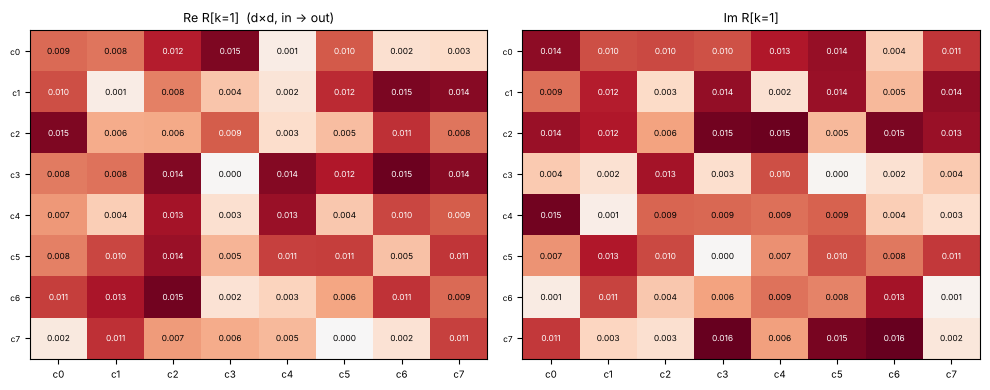

v̂_1 (8 channels)          : [-0.127-0.02j   0.168+0.073j -0.217-0.024j  0.223+0.074j  0.45 +0.198j
 -0.324-0.21j  -0.096-0.276j  0.053+0.136j]
R[1][:, c0] (8 inputs)      : [0.009+0.014j 0.01 +0.009j 0.015+0.014j 0.008+0.004j 0.007+0.015j
 0.008+0.007j 0.011+0.001j 0.002+0.011j]
(R v̂)_1,c0 by hand = sum of 8 complex products = -0.0043+0.0004j
(R v̂)_1,c0 from the model                       = -0.0043+0.0004j


In [8]:
L1 = params0["layers"][0]
R = np.asarray(L1["R_re"]) + 1j * np.asarray(L1["R_im"])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
viz.complex_weights(axes[0], axes[1], R[1], 1)
plt.tight_layout(); plt.show()

vk = np.asarray(tr.v_hat_kept[0][1])          # the k = 1 row: 8 complex numbers
products = vk * R[1][:, 0]                      # v̂_{1,i} · R[1]_{i,0}
print("v̂_1 (8 channels)          :", np.round(vk, 3))
print("R[1][:, c0] (8 inputs)      :", np.round(R[1][:, 0], 3))
print(f"(R v̂)_1,c0 by hand = sum of 8 complex products = {products.sum():.4f}")
print(f"(R v̂)_1,c0 from the model                       = {complex(tr.Rv_hat[0][1, 0]):.4f}")

### 4e. Inverse FFT: back to the grid

The 8 modified modes are put back in place, modes 8..16 are **zero**, and the inverse real FFT returns 32 values per
channel. With the $1/N$ already on the forward transform, the inverse is the plain sum of waves:

$$
(\mathcal K v)(x_j) = \mathrm{Re}\,\hat w_0 + 2\,\mathrm{Re}\sum_{k=1}^{7} \hat w_k\, e^{2\pi i k j/N},
\qquad \hat w = R\hat v .
$$

(The imaginary part of $\hat w_0$ is dropped: a real function has a real mean.) Worked example: **point $x_5$,
channel c0**.

contribution of each mode k=0..7: [-0.0042 -0.0054 -0.0011 -0.0026 -0.0016  0.0003 -0.0001 -0.0004]
(K v)(x5), c0 by hand = -0.0151
(K v)(x5), c0 model   = -0.0151


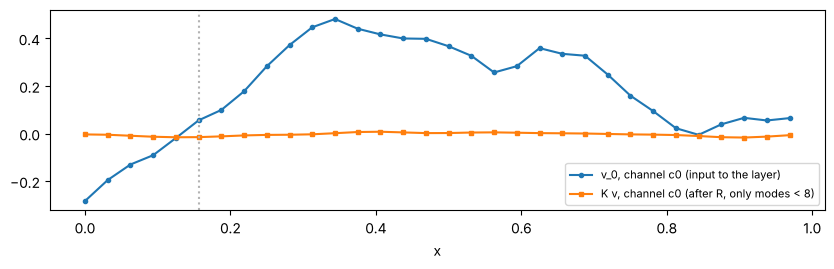

In [9]:
w = np.asarray(tr.Rv_hat[0][:, 0])            # 8 modes of channel c0
j = 5
waves = w[1:] * np.exp(2j * np.pi * np.arange(1, 8) * j / N)
by_hand = w[0].real + 2 * waves.real.sum()
print("contribution of each mode k=0..7:", np.round(np.r_[w[0].real, 2 * waves.real], 4))
print(f"(K v)(x{j}), c0 by hand = {by_hand:.4f}")
print(f"(K v)(x{j}), c0 model   = {float(tr.spectral[0][j, 0]):.4f}")

fig, ax = plt.subplots(figsize=(10, 2.6))
ax.plot(x, tr.lifted[:, 0], "o-", ms=3, label="v_0, channel c0 (input to the layer)")
ax.plot(x, tr.spectral[0][:, 0], "s-", ms=3, label="K v, channel c0 (after R, only modes < 8)")
ax.axvline(x[j], color="0.7", ls=":"); ax.legend(fontsize=8); ax.set_xlabel("x"); plt.show()

### 4f. Pointwise W, the sum, and the activation

The **local** path is a plain $8 \times 8$ matrix $W$ plus bias, applied to every row of $v$ separately (a
$1\times1$ convolution, exactly like $P$). It is not truncated, so it carries all frequencies and the exact local
value. The layer output is

$$
v_{1}(x_j) = \mathrm{GELU}\big((\mathcal K v_0)(x_j) + v_0(x_j)\,W + b\big).
$$

GELU is a smooth ReLU: $\mathrm{GELU}(z) = z\,\Phi(z)$. Being nonlinear, it creates new frequencies (e.g. it turns
a pure wave $\sin 2\pi x$ into something with harmonics), and the next layer's FFT sees them. Worked example: row
$x_5$, channel c0.

In [10]:
Wm, bm = np.asarray(L1["W"]), np.asarray(L1["b"])
j = 5
local = v0[j] @ Wm[:, 0] + bm[0]
pre = float(tr.spectral[0][j, 0]) + local
gelu = float(jax.nn.gelu(pre))
print(f"W path:  v_0[x{j}] · W[:, c0] + b[c0] = {local:.4f}    (model: {float(tr.local[0][j, 0]):.4f})")
print(f"sum:     K v + W v + b              = {pre:.4f}    (model: {float(tr.pre_act[0][j, 0]):.4f})")
print(f"GELU:    {pre:.4f} · Φ({pre:.4f})         = {gelu:.4f}    (model: {float(tr.v[0][j, 0]):.4f})")

W path:  v_0[x5] · W[:, c0] + b[c0] = 0.0717    (model: 0.0717)
sum:     K v + W v + b              = 0.0566    (model: 0.0566)
GELU:    0.0566 · Φ(0.0566)         = 0.0296    (model: 0.0296)


### 4g. The whole Fourier layer in one picture

Top row, left to right: the input $v_0$, its Fourier magnitudes with the kept box, the kept modes after $R$, and
$\mathcal K v$ back on the grid. Bottom row: the local path $Wv + b$, the sum, and the output after GELU. Layers 2,
3 and 4 are the same picture with their own $R, W, b$ (use `viz.fourier_layer_flow(tr, t, cfg.modes)`).

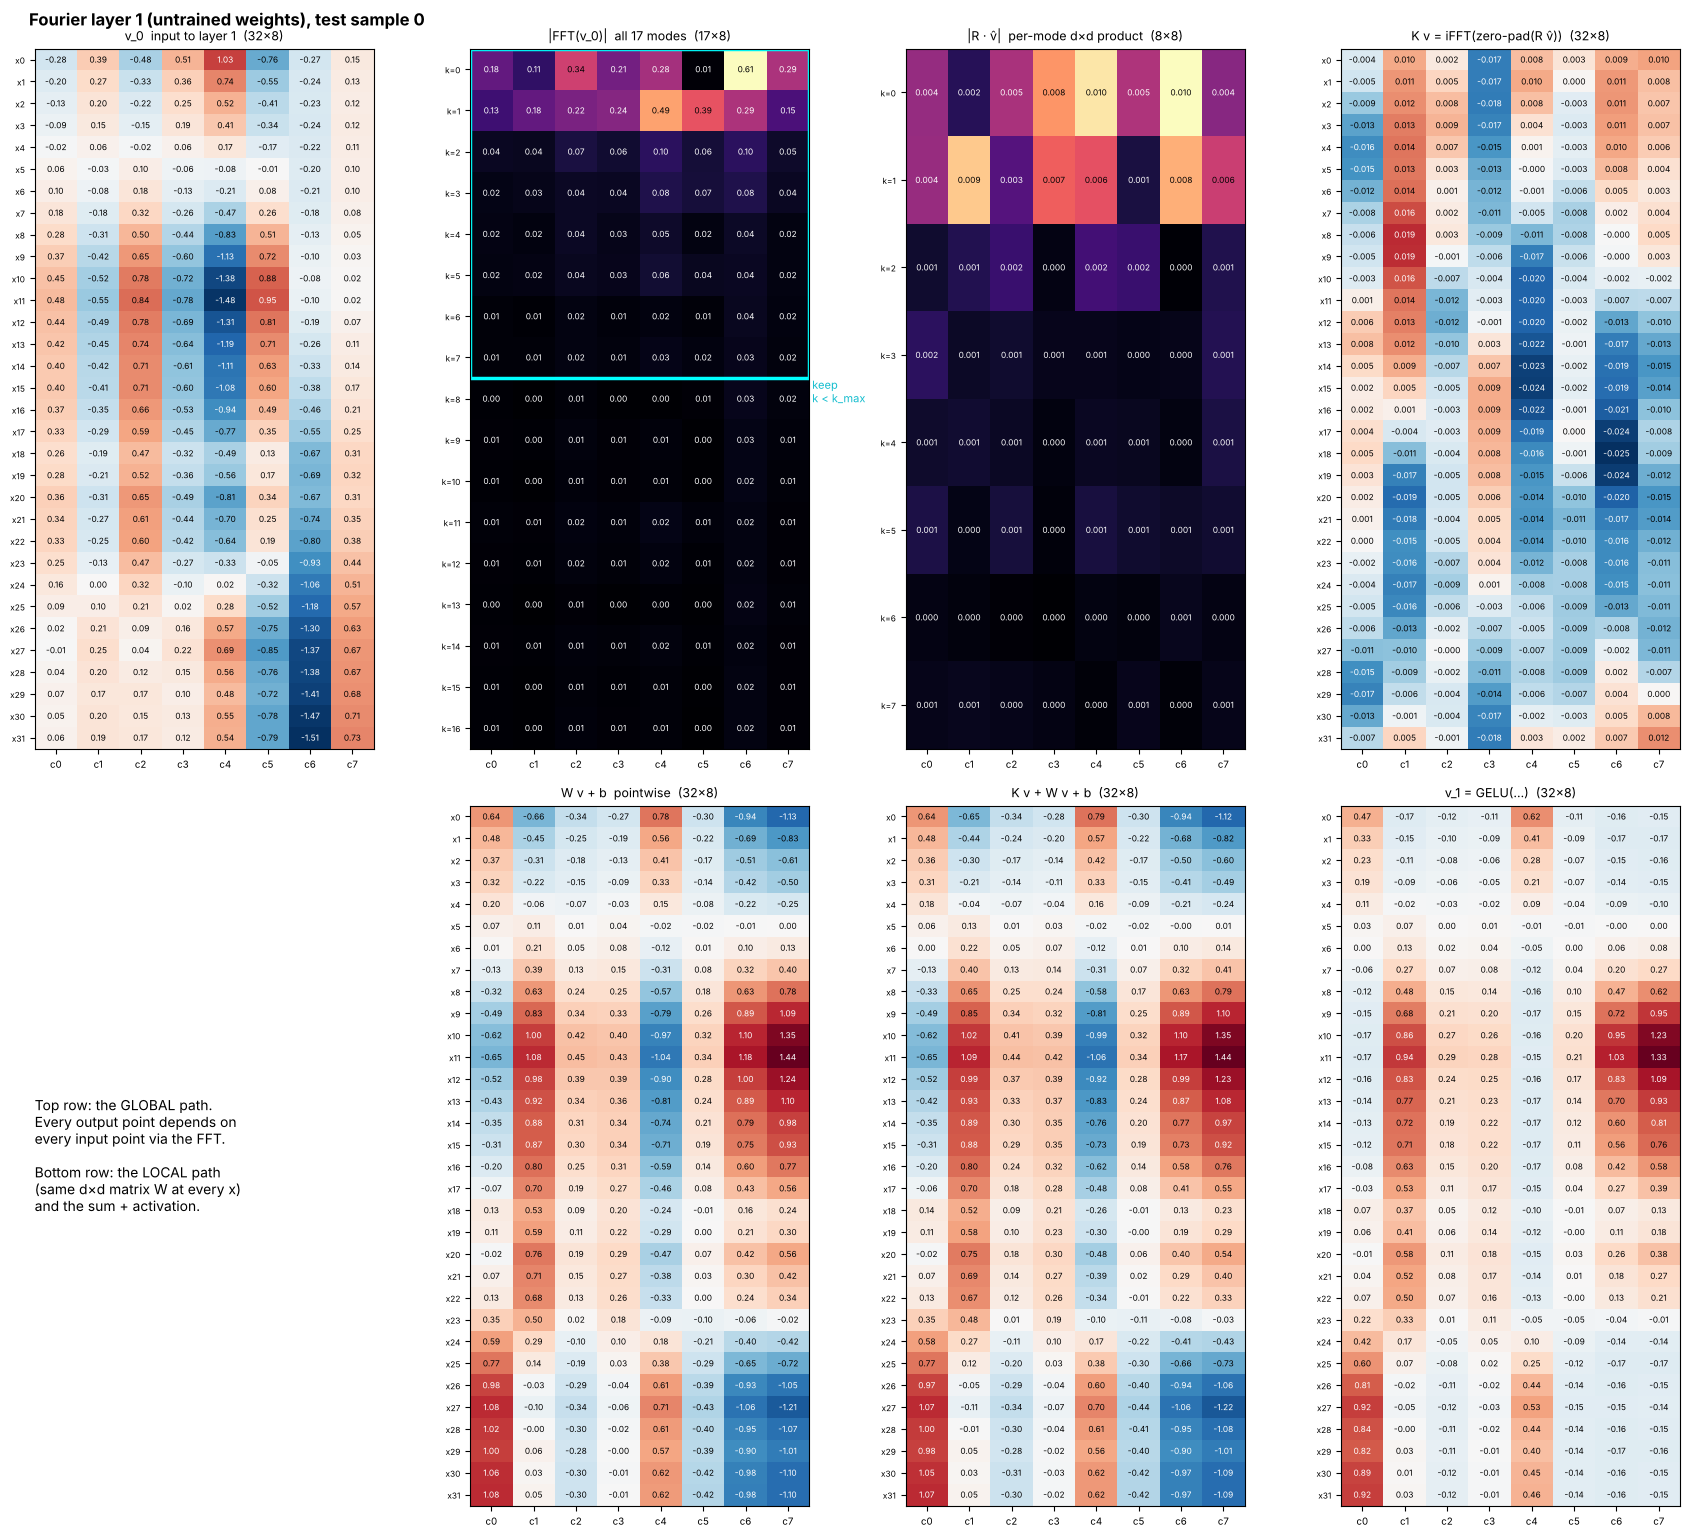

In [11]:
viz.fourier_layer_flow(tr, 0, cfg.modes, "Fourier layer 1 (untrained weights), test sample 0")
plt.show()

### 4h. Project Q: from 8 channels back to one number per point

After the 4th layer, a small pointwise MLP $Q$ ($8 \to 32 \to 1$, GELU in the middle; the paper uses
$64 \to 128 \to 1$) reads the 8 channels at each point and outputs $u(x_j, 1)$. Like $P$ and $W$ it never mixes
grid points; all the spatial communication happened in the Fourier layers.

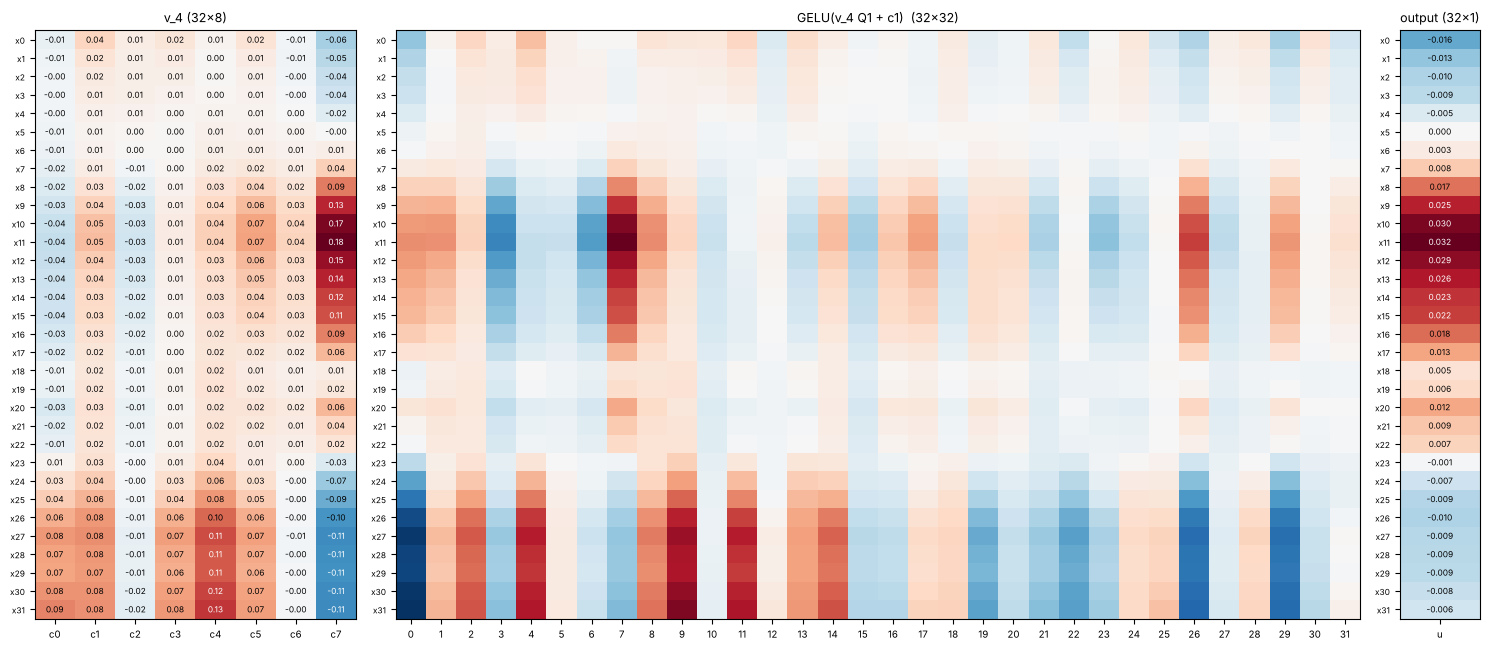

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6.6), gridspec_kw=dict(width_ratios=[8, 24, 2]))
viz.matrix(axes[0], tr.v[-1], viz.grid_labels(N), viz.channel_labels(8), "v_4 (32×8)")
viz.matrix(axes[1], tr.proj_hidden, viz.grid_labels(N), None, "GELU(v_4 Q1 + c1)  (32×32)", annotate=False)
viz.matrix(axes[2], np.asarray(tr.output)[:, None], viz.grid_labels(N), ["u"], "output (32×1)")
plt.tight_layout(); plt.show()

## 5. The loss, and where the gradient comes from

The paper trains with the **relative $L^2$ error** (Sec. 5):

$$
\mathcal L(\theta) = \frac1B \sum_{b=1}^{B} \frac{\big\|G_\theta(a_b) - u_b\big\|_2}{\|u_b\|_2}.
$$

Dividing by $\|u_b\|$ makes samples with small and large amplitudes count equally, and makes the number independent
of the grid size: on a finer grid both norms grow by the same factor. That is what lets us compare errors at 32 and
256 points in section 8.

The gradient $\partial \mathcal L / \partial \theta$ is ordinary **reverse-mode autodiff** (backprop) through the
forward pass of section 4. There is no PDE inside the network and no adjoint equation to solve. (More on this in
section 9.)

Worked example with the untrained network on test sample 0:

In [13]:
pred, target = np.asarray(tr.output), np.asarray(u_test[0])
num, den = np.linalg.norm(pred - target), np.linalg.norm(target)
print(f"||pred - u|| = {num:.4f},  ||u|| = {den:.4f},  relative L2 = {num / den:.4f}")
print(f"relative_l2 from src.training       = {float(relative_l2(pred, target)):.4f}")
print(f"batch loss on 200 test samples      = {evaluate(params0, a_test, u_test):.4f}   (1.0 = as bad as predicting 0)")

grads = jax.grad(batch_loss)(params0, a_test[:32], u_test[:32])
print("\ngradient pytree has the same shape as the parameters, e.g. dL/dR_re of layer 1:",
      grads["layers"][0]["R_re"].shape)

||pred - u|| = 0.8722,  ||u|| = 0.9372,  relative L2 = 0.9306
relative_l2 from src.training       = 0.9306


batch loss on 200 test samples      = 0.9199   (1.0 = as bad as predicting 0)



gradient pytree has the same shape as the parameters, e.g. dL/dR_re of layer 1: (8, 8, 8)


## 6. Train it (and keep snapshots)

1000 training pairs at $N = 32$, mini-batches of 32, Adam with a cosine learning-rate decay. A copy of the weights
is kept every 100 steps so the explorer can show the tensors at any point in training.

step   500   relative L2 (train batch) = 0.0112


step  1000   relative L2 (train batch) = 0.0139


step  1500   relative L2 (train batch) = 0.0117


step  2000   relative L2 (train batch) = 0.0061


step  2500   relative L2 (train batch) = 0.0046


step  3000   relative L2 (train batch) = 0.0047
trained in 8 s


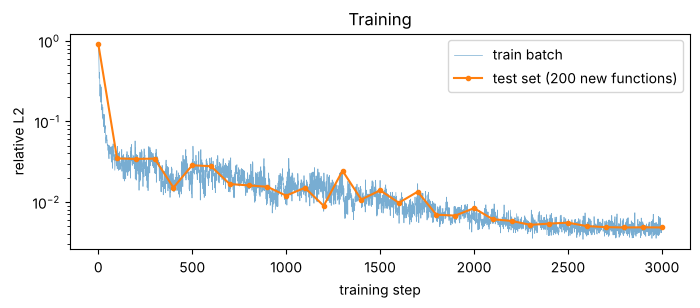

final test relative L2 error: 0.0048


In [14]:
t0 = time.time()
params, snapshots, snap_steps, losses = train(params0, a_train, u_train, n_steps=3000, batch_size=32,
                                              lr=5e-3, snapshot_every=100, log_every=500)
print(f"trained in {time.time() - t0:.0f} s")

test_err = [evaluate(p, a_test, u_test) for p in snapshots]
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.semilogy(losses, lw=0.5, alpha=0.6, label="train batch")
ax.semilogy(snap_steps, test_err, "o-", ms=3, label="test set (200 new functions)")
ax.set_xlabel("training step"); ax.set_ylabel("relative L2"); ax.legend(); ax.set_title("Training")
plt.show()
print(f"final test relative L2 error: {test_err[-1]:.4f}")

## 7. Interactive explorer: what is inside the network, at any point of training?

Three sliders:

* **training step**: which weight snapshot to use (0 = random weights, 3000 = trained).
* **test sample**: which of the 200 unseen input functions is fed in.
* **layer**: which of the 4 Fourier layers to show.

Top left: input $u_0$, true $u(x,1)$ and the prediction. The heatmaps are the chosen layer's tensors: $|\hat v|$
(all 17 modes, the kept ones above the cyan line), $|R\hat v|$, the global part $\mathcal K v$, the local part
$Wv + b$ and the output $v_{t+1}$.

Things to try:

* At training step 0 the prediction is a flat line near zero. Drag the training step and watch it bend into place
  within the first few hundred steps.
* Look at $|\hat v|$ of the trained network: the energy sits in the low modes. The cut at $k_{max}$ loses little.
* Compare $\mathcal K v$ (smooth, only 8 modes) with $Wv + b$ (can be sharp, carries the local value). The output
  needs both.

In [15]:
import ipywidgets as w

traces = {}
def get_trace(k, i):
    if (k, i) not in traces:
        traces[(k, i)] = apply_with_trace(snapshots[k], a_test[i])
    return traces[(k, i)]

def explore(snapshot, sample, layer):
    tr = get_trace(snapshot, sample)
    t = layer - 1
    v_in = tr.lifted if t == 0 else tr.v[t - 1]
    fig = plt.figure(figsize=(17, 6.2))
    gs = fig.add_gridspec(2, 6, height_ratios=[1, 2.4])
    ax = fig.add_subplot(gs[0, :])
    ax.plot(x, a_test[sample], color="0.6", label="input u0")
    ax.plot(x, u_test[sample], "k-", lw=2, label="true u(x,1)")
    ax.plot(x, tr.output, "r--", lw=2, label="FNO prediction")
    err = float(relative_l2(tr.output, u_test[sample]))
    ax.set_title(f"training step {snap_steps[snapshot]}, test sample {sample}: relative L2 = {err:.3f}")
    ax.legend(fontsize=8, ncol=3); ax.set_xlim(0, 1)
    ch = viz.channel_labels(cfg.width)
    panels = [(v_in, f"v_{t} (input)", "RdBu_r", viz.grid_labels(N)),
              (np.abs(tr.v_hat[t]), "|FFT v|", "magma", viz.mode_labels(17)),
              (np.abs(tr.Rv_hat[t]), "|R v̂|", "magma", viz.mode_labels(cfg.modes)),
              (tr.spectral[t], "K v (global)", "RdBu_r", viz.grid_labels(N)),
              (tr.local[t], "W v + b (local)", "RdBu_r", viz.grid_labels(N)),
              (tr.v[t], f"v_{t + 1} (output)", "RdBu_r", viz.grid_labels(N))]
    for c, (M, title, cmap, rows) in enumerate(panels):
        a = fig.add_subplot(gs[1, c])
        viz.matrix(a, M, rows, ch, title, cmap=cmap, annotate=False)
        if title == "|FFT v|":
            a.axhline(cfg.modes - 0.5, color="cyan", lw=2)
    plt.tight_layout(); plt.show()

w.interact(explore,
           snapshot=w.IntSlider(min=0, max=len(snapshots) - 1, value=len(snapshots) - 1, description="train step #"),
           sample=w.IntSlider(min=0, max=len(a_test) - 1, value=0, description="test sample"),
           layer=w.IntSlider(min=1, max=cfg.layers, value=1, description="layer"));

interactive(children=(IntSlider(value=30, description='train step #', max=30), IntSlider(value=0, description=…

### Static version: the same test sample at three points in training (layer 1)

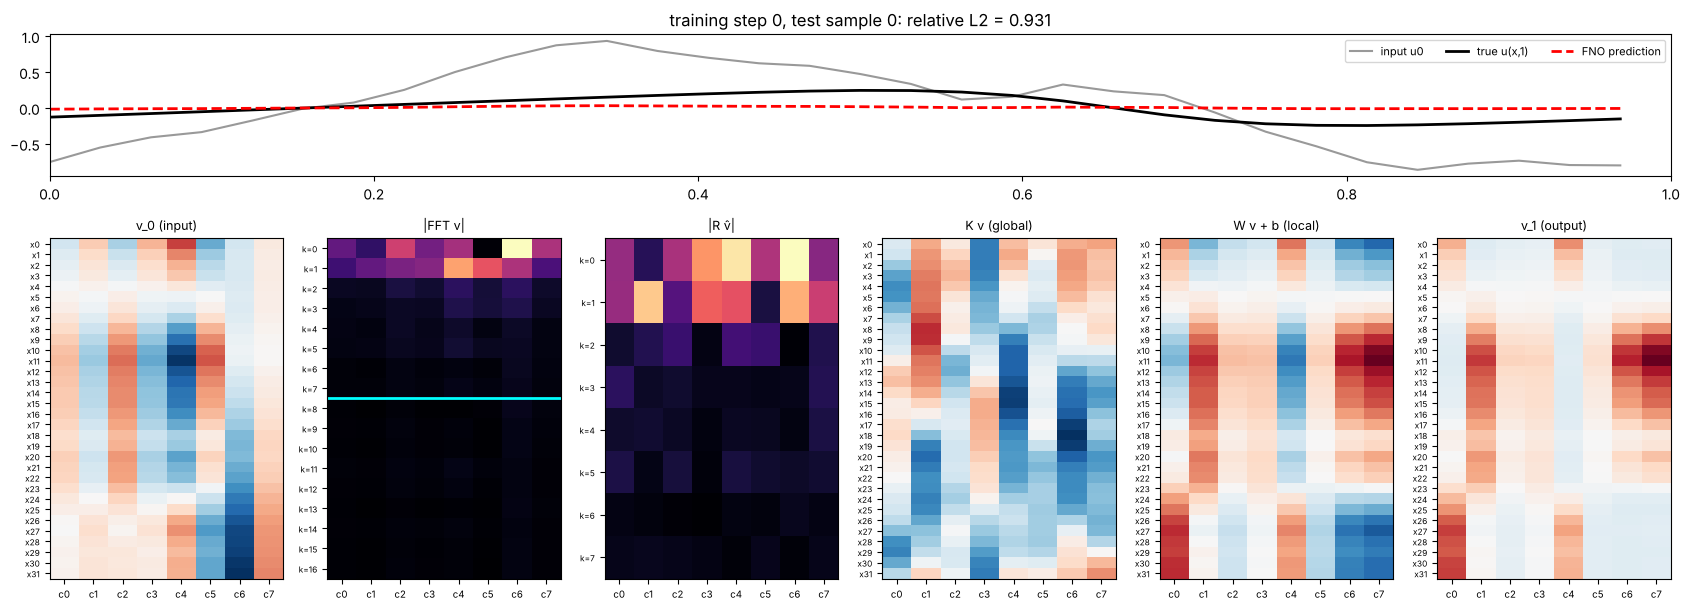

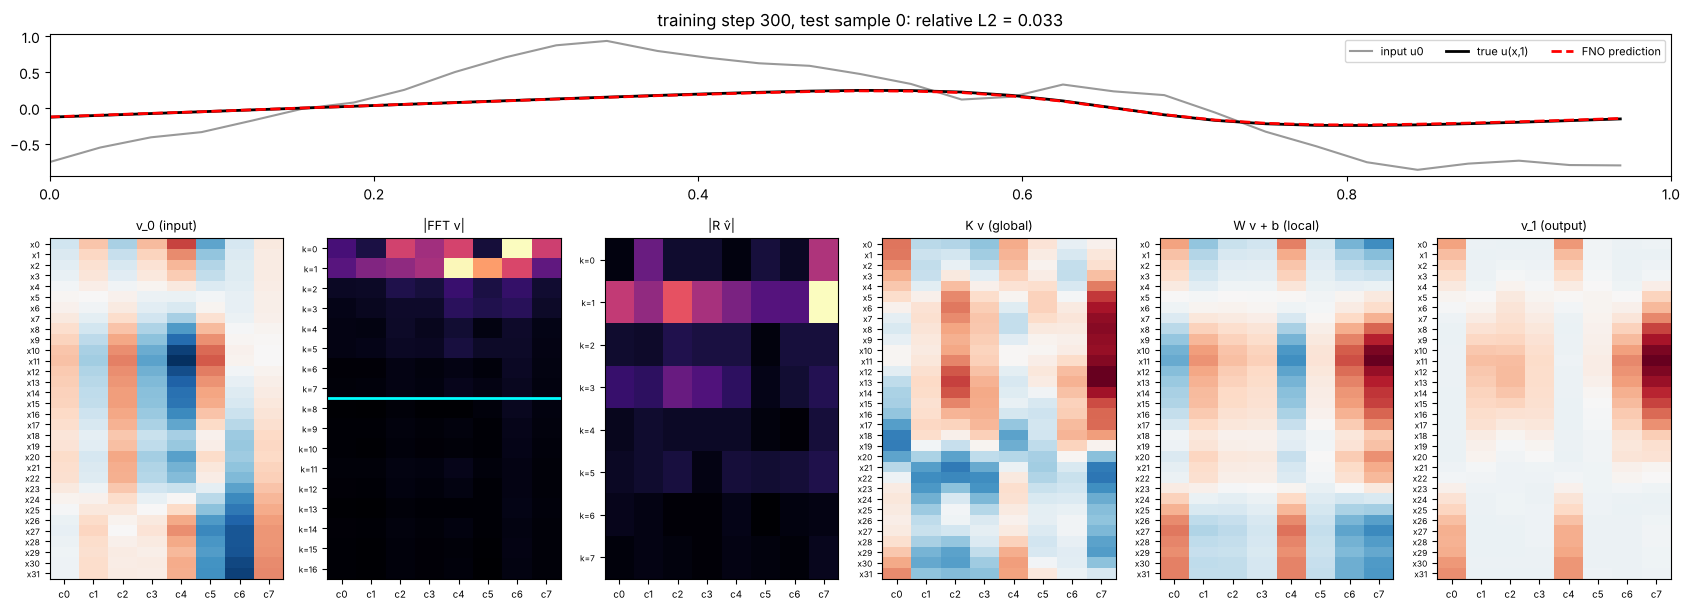

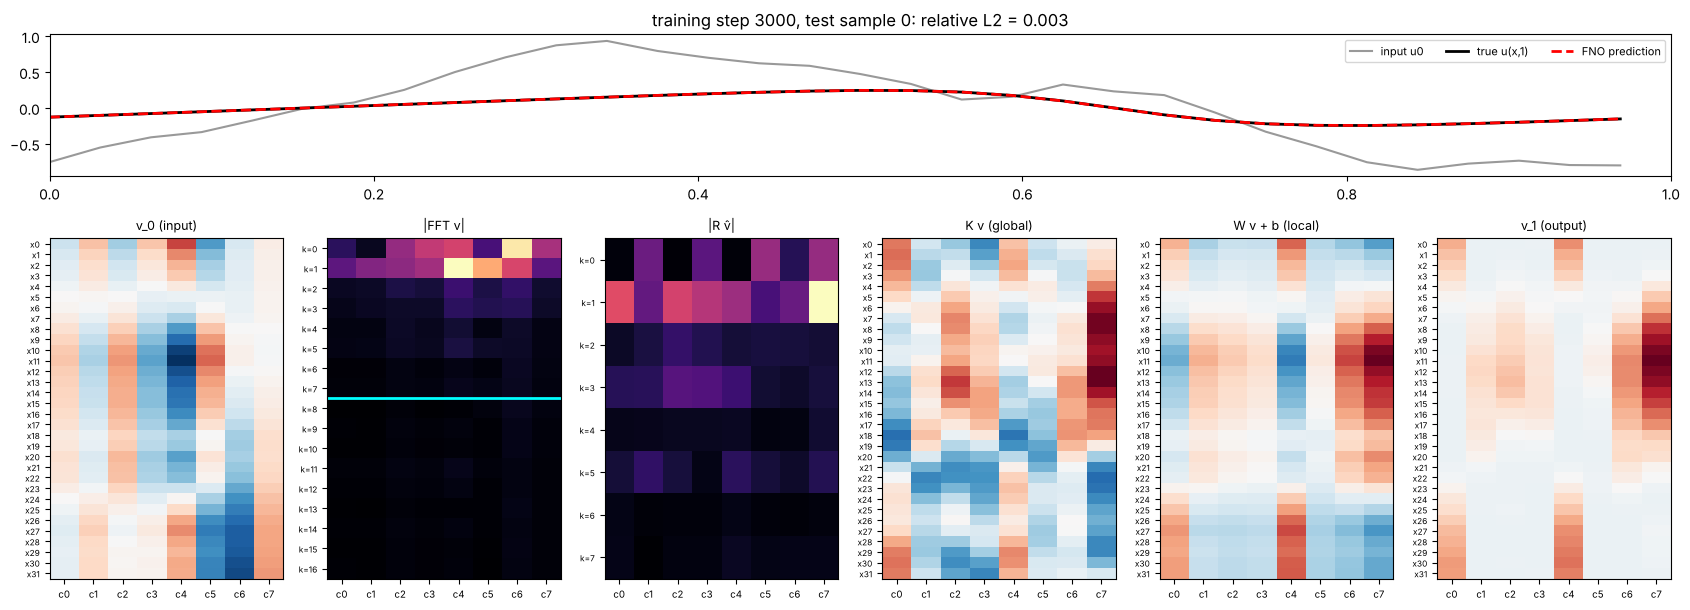

In [16]:
for k in [0, 3, len(snapshots) - 1]:
    explore(k, 0, 1)

### The trained first layer, with numbers

The same picture as section 4g, now with the trained weights.

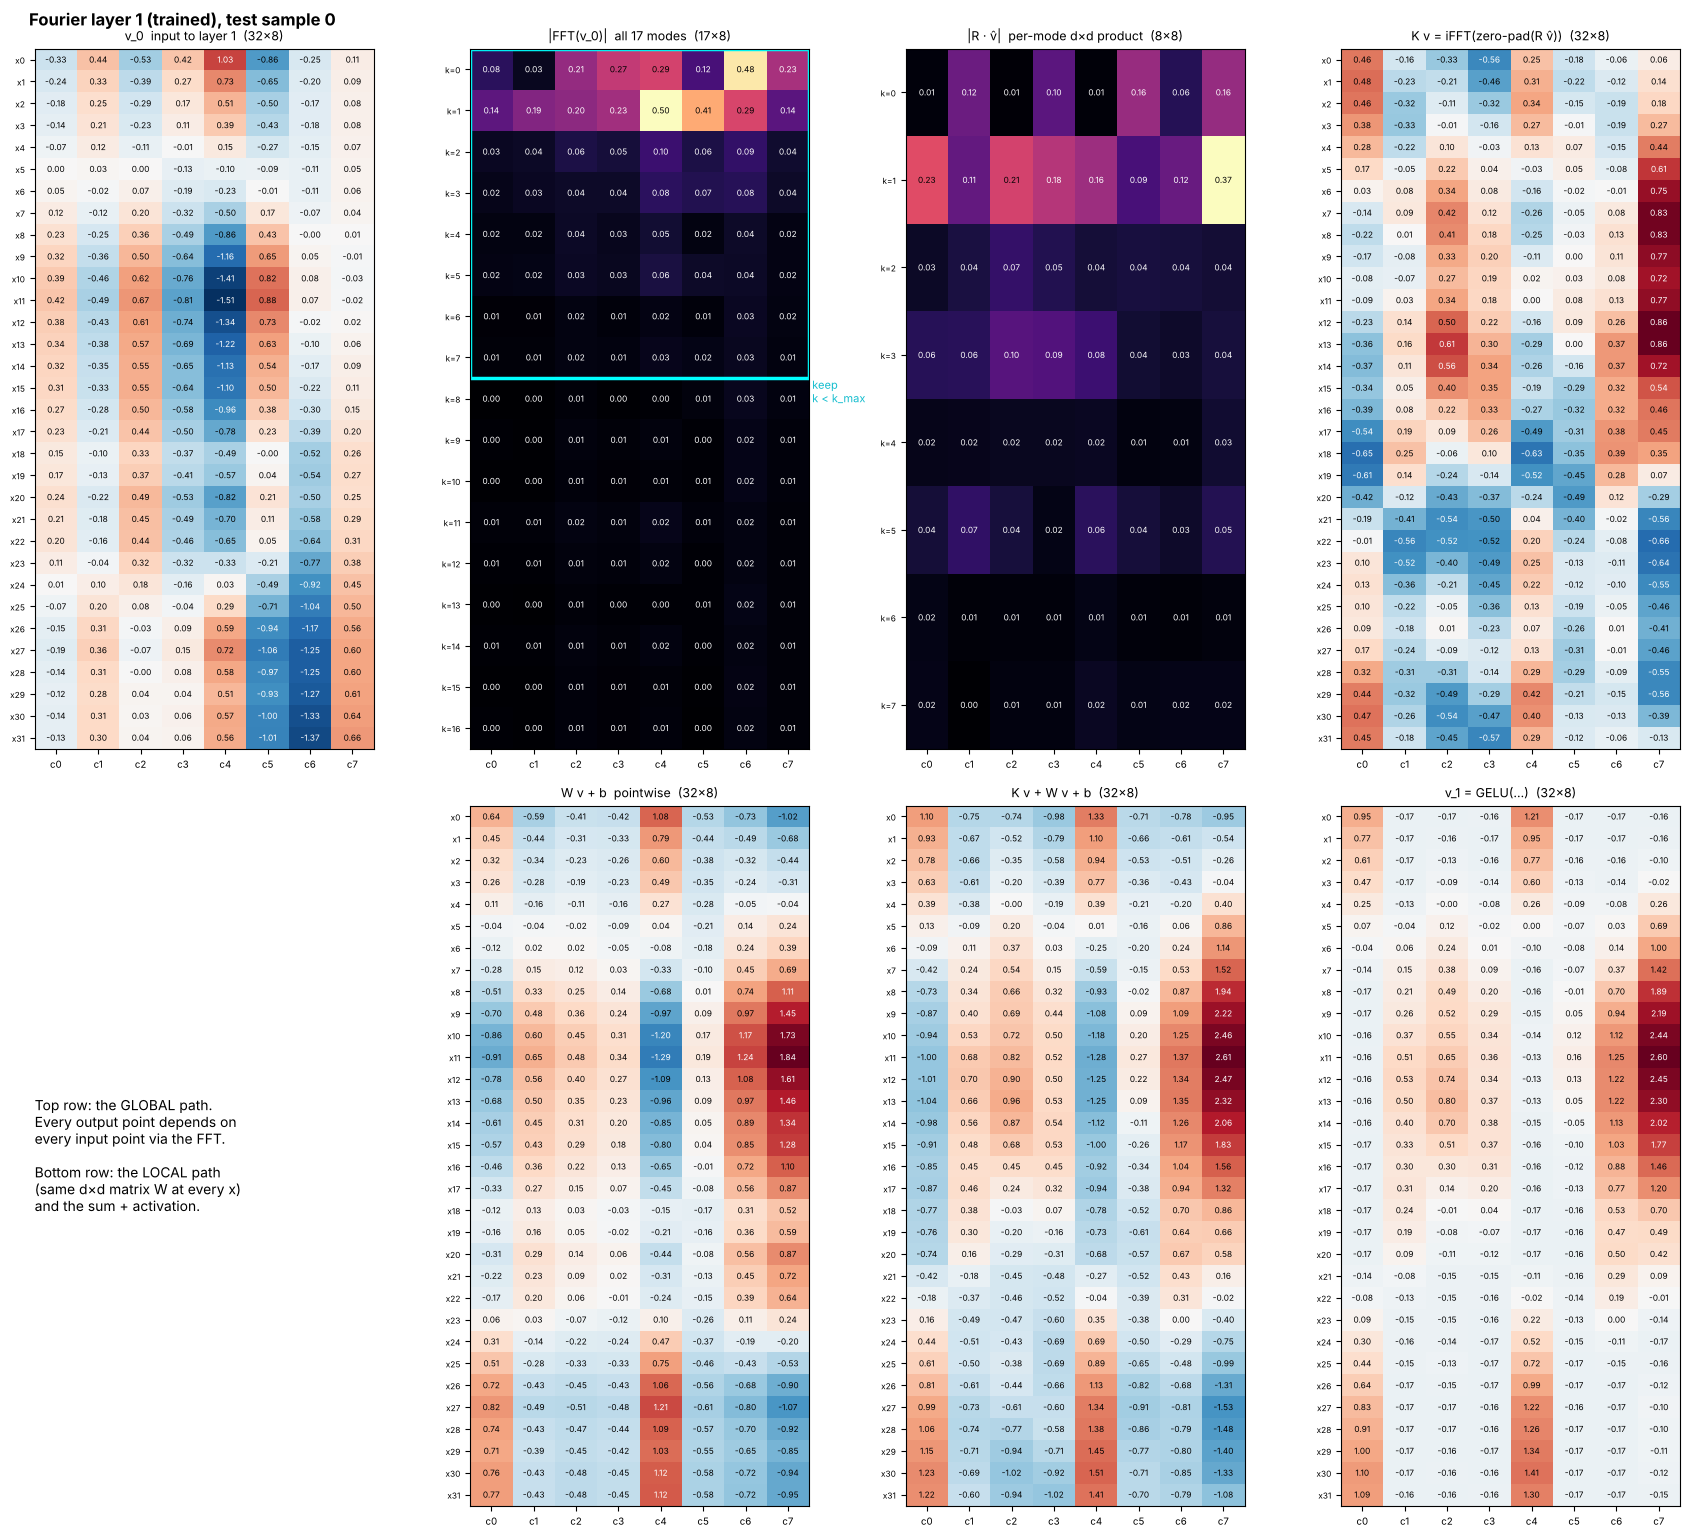

In [17]:
viz.fourier_layer_flow(apply_with_trace(params, a_test[0]), 0, cfg.modes, "Fourier layer 1 (trained), test sample 0")
plt.show()

## 8. What did it learn?

### 8a. Predictions on functions it has never seen

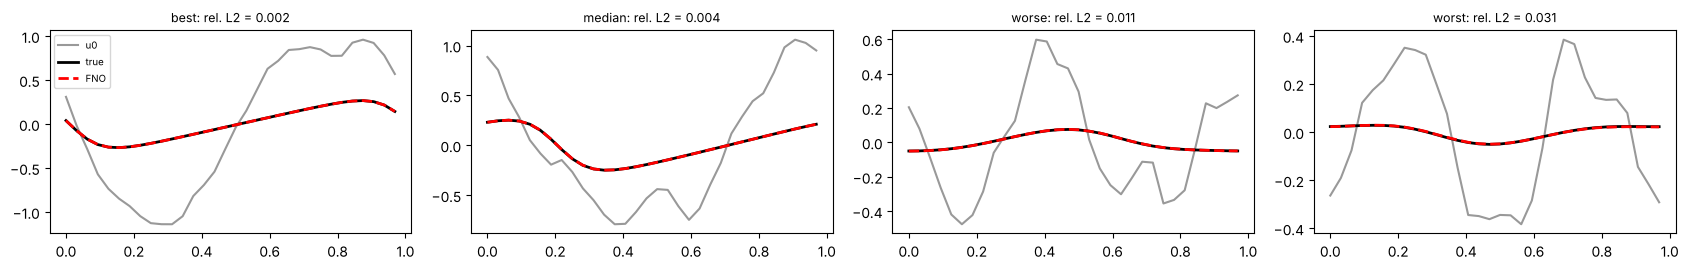

test relative L2: mean 0.0048, median 0.0037  (paper, nu=0.1, d=64, k_max=16, 8192 points: ~0.002)


In [18]:
pred_test = jax.vmap(apply, in_axes=(None, 0))(params, a_test)
errs = np.asarray(relative_l2(pred_test, u_test))
order = np.argsort(errs)
fig, axes = plt.subplots(1, 4, figsize=(17, 2.8))
for ax, i, tag in zip(axes, [order[0], order[len(order) // 2], order[-10], order[-1]], ["best", "median", "worse", "worst"]):
    ax.plot(x, a_test[i], color="0.6", label="u0"); ax.plot(x, u_test[i], "k-", lw=2, label="true")
    ax.plot(x, pred_test[i], "r--", lw=2, label="FNO"); ax.set_title(f"{tag}: rel. L2 = {errs[i]:.3f}", fontsize=9)
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()
print(f"test relative L2: mean {errs.mean():.4f}, median {np.median(errs):.4f}  (paper, nu=0.1, d=64, k_max=16, 8192 points: ~0.002)")

### 8b. Zero-shot super-resolution: same weights, finer grid

The model was trained only on 32-point grids. Nothing in it has size 32: $P$, $W$, $Q$ act per point and $R$ acts
on modes $0..7$, which are the same waves on any grid. So we can feed it the 64-, 128- and 256-point versions of
the test functions directly (paper Sec. 5.4 and Fig. 1).

N =  32: test relative L2 = 0.0048


N =  64: test relative L2 = 0.0035


N = 128: test relative L2 = 0.0035


N = 256: test relative L2 = 0.0035


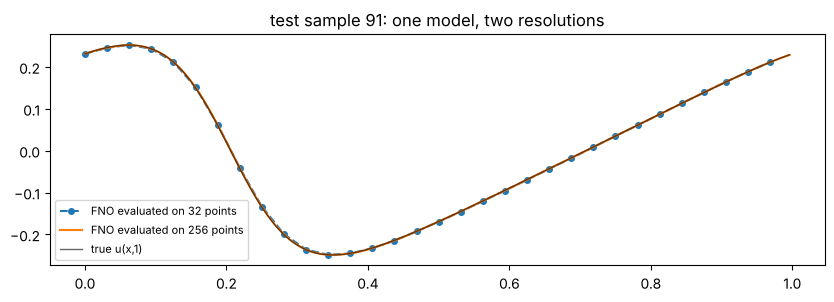

In [19]:
fig, ax = plt.subplots(figsize=(10, 3))
i = int(order[len(order) // 2])
for n_eval in [32, 64, 128, 256]:
    s_eval = phys.n_fine // n_eval
    a_e, u_e = data["a"][1000:, ::s_eval], data["u"][1000:, ::s_eval]
    print(f"N = {n_eval:3d}: test relative L2 = {evaluate(params, a_e, u_e):.4f}")
    if n_eval in (32, 256):
        ax.plot(np.asarray(grid(n_eval)), apply(params, a_e[i]), "o--" if n_eval == 32 else "-", ms=4,
                label=f"FNO evaluated on {n_eval} points")
ax.plot(x_fine, data["u"][1000 + i], "k", lw=1, alpha=0.6, label="true u(x,1)")
ax.legend(fontsize=8); ax.set_title(f"test sample {i}: one model, two resolutions"); plt.show()

The error barely changes with resolution. A CNN trained on 32 pixels has kernels of a fixed size *in pixels*; on a
finer grid the same kernel covers a smaller physical region and the model breaks. FNO's weights live in
function space.

Caveat (also in the paper discussion): "super-resolution" here means *evaluating* at more points. The output still
has no detail above what the model learned to produce; it cannot invent physics it never saw.

### 8c. What does R look like after training?

$|R[k]|$ (Frobenius norm of each mode's $8\times8$ matrix) per layer: how strongly each layer passes each
frequency.

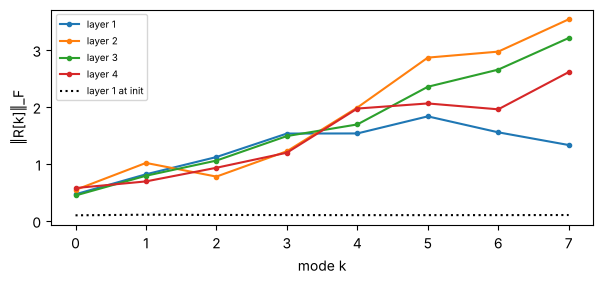

In [20]:
fig, ax = plt.subplots(figsize=(7, 2.8))
for t, layer in enumerate(params["layers"]):
    Rt = np.asarray(layer["R_re"]) + 1j * np.asarray(layer["R_im"])
    ax.plot(np.linalg.norm(Rt, axis=(1, 2)), "o-", ms=3, label=f"layer {t + 1}")
R0 = np.asarray(params0["layers"][0]["R_re"]) + 1j * np.asarray(params0["layers"][0]["R_im"])
ax.plot(np.linalg.norm(R0, axis=(1, 2)), "k:", label="layer 1 at init")
ax.set_xlabel("mode k"); ax.set_ylabel("‖R[k]‖_F"); ax.legend(fontsize=7); plt.show()

## 9. Does the FNO have anything to do with the adjoint method?

**Short answer: not by design.** The adjoint method
([`01-differentiable-simulation/adjoint`](../../../01-differentiable-simulation/adjoint/)) computes the gradient of
an objective through a *simulator* by solving a second, backward-in-time equation. The FNO is not trained that way.
It is trained on input/output pairs and its gradient (section 5) is ordinary backprop through FFTs and small
matrices. No adjoint PDE appears anywhere.

**But they meet in two places.**

1. **The FFT's adjoint is the inverse FFT.** With orthonormal scaling the DFT matrix $F$ is unitary,
   $F^{H} F = I$, so $F^{H} = F^{-1}$. Backprop through a Fourier layer therefore runs an FFT where the forward pass
   ran an inverse FFT and vice versa: the backward pass of a Fourier layer is another Fourier layer, and costs the
   same $O(N\log N)$.
2. **A trained FNO is a differentiable surrogate.** Inverse and design problems need $\partial J / \partial u_0$
   for some objective $J$ of the solution. The adjoint method gets it by a backward solve through the simulator;
   with a trained FNO you get it by backprop through the network, about as cheaply as one forward pass. The paper
   uses the FNO inside a Bayesian inverse problem this way (Sec. 5.5).

The catch: the FNO was trained to match **values** of $G$, not its **derivatives**. Nothing guarantees that
$\nabla_{u_0} J$ through the FNO matches the true one. The cells below check both points.

In [21]:
# 1. The DFT matrix (orthonormal) is unitary: its adjoint (conjugate transpose) is its inverse.
F = np.fft.fft(np.eye(N), norm="ortho")
print("max |F^H F - I|          =", np.abs(F.conj().T @ F - np.eye(N)).max().round(12))
print("max |F^H - inverse DFT|  =", np.abs(F.conj().T - np.fft.ifft(np.eye(N), norm="ortho")).max().round(12))

max |F^H F - I|          = 0.0
max |F^H - inverse DFT|  = 0.0


**2. Gradient through the FNO vs gradient through the solver.** Objective: $J(u_0) = u(x{=}0.5,\, t{=}1)$, the
solution at the middle of the domain. $\partial J / \partial u_0(x_j)$ says how much nudging the initial condition
at $x_j$ moves that one value. Through the real solver this is exactly what an adjoint solve computes (here JAX's
reverse mode through the time-stepping loop does it for us, which is the discrete adjoint). Through the FNO it is
backprop through the network.

To compare like with like, both take the 32-point $u_0$: the solver first interpolates it spectrally onto its 256
points.

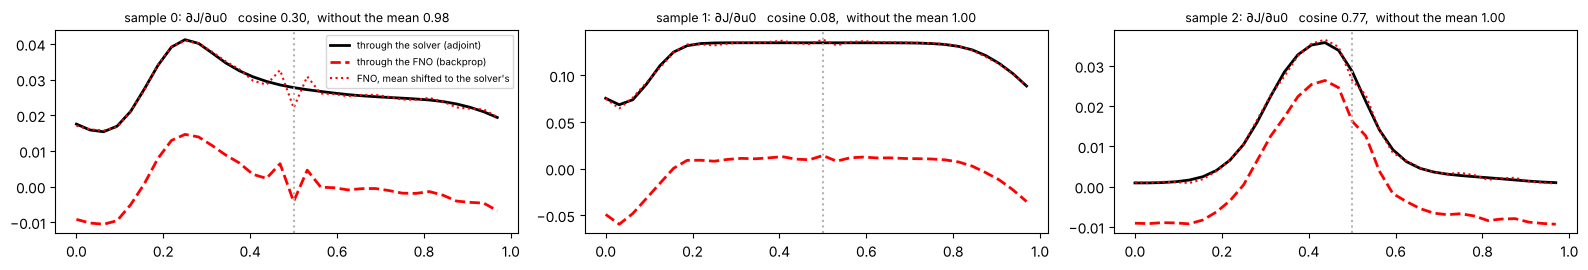

gradient through the solver: 55.47 ms
gradient through the FNO   : 0.31 ms


In [22]:
def J_solver(a32):
    a_hat = jnp.fft.rfft(a32, norm="forward")
    a256 = jnp.fft.irfft(jnp.zeros(phys.n_fine // 2 + 1, complex).at[: N // 2 + 1].set(a_hat), n=phys.n_fine, norm="forward")
    return solve(a256, phys)[phys.n_fine // 2]

def J_fno(a32):
    return apply(params, a32)[N // 2]

g_solver, g_fno = jax.jit(jax.grad(J_solver)), jax.jit(jax.grad(J_fno))
fig, axes = plt.subplots(1, 3, figsize=(16, 2.8))
for ax, i in zip(axes, [0, 1, 2]):
    gs_, gf = np.asarray(g_solver(a_test[i])), np.asarray(g_fno(a_test[i]))
    cos = lambda p, q: float(p @ q / (np.linalg.norm(p) * np.linalg.norm(q)))
    ax.plot(x, gs_, "k-", lw=2, label="through the solver (adjoint)")
    ax.plot(x, gf, "r--", lw=2, label="through the FNO (backprop)")
    ax.plot(x, gf - gf.mean() + gs_.mean(), "r:", lw=1.5, label="FNO, mean shifted to the solver's")
    ax.axvline(0.5, color="0.7", ls=":")
    ax.set_title(f"sample {i}: ∂J/∂u0   cosine {cos(gs_, gf):.2f},  without the mean {cos(gs_ - gs_.mean(), gf - gf.mean()):.2f}", fontsize=9)
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

for f, name in [(g_solver, "solver"), (g_fno, "FNO")]:
    f(a_test[3]).block_until_ready(); t0 = time.perf_counter()
    for i in range(20): f(a_test[i]).block_until_ready()
    print(f"gradient through the {name:6s}: {(time.perf_counter() - t0) / 20 * 1e3:.2f} ms")

**Reading the plot.** The true sensitivity (black) shows which part of the initial condition decides
$u(0.5, 1)$: the stretch of $u_0$ that the flow carried to the centre, smeared by viscosity. It depends on the
sample, because Burgers is nonlinear. The FNO's gradient (red) has the right **shape**, but it is shifted down by
a constant. Removing the mean (dotted red) makes the two curves line up almost exactly (cosine similarity
0.98 to 1.00). The small wiggle right at $x = 0.5$ in sample 0 is the pointwise $W$ path, which connects $u_0(0.5)$
directly to the output at the same point.

Why a constant? Every training input has zero mean (the random field has no $k = 0$ mode, and Burgers conserves the
mean, so the targets have none either: see the spectrum in section 4c). The FNO never saw what happens when you add
a constant to $u_0$, so its derivative in that one direction is whatever the weights happen to give. A gradient asks
"what if the input changed a little, in *any* direction?", including directions the training data never explored.
Matching values on the data does not pin down derivatives off the data.

The FNO gradient is also about two orders of magnitude cheaper than differentiating through 1000 solver steps.

That gap is a research question in its own right: training operators so that their **gradients** are also
faithful (e.g. adding derivative supervision from a differentiable solver) is what makes them trustworthy inside
adjoint-style design loops.

## Takeaways, connected to the paper

* **Learn the operator, not one solution.** One trained model maps *any* initial condition from the distribution to
  its solution at $t = 1$, in one forward pass.
* **Fourier layer = learned global convolution.** FFT → keep $k_{max}$ modes → per-mode $d\times d$ complex matrix
  $R[k]$ → inverse FFT, plus a pointwise $W$. Global receptive field at $O(N \log N)$ cost.
* **Pointwise + modes ⇒ resolution-independent.** $P$, $W$, $Q$ act per point, $R$ acts on physical frequencies, so
  the weights trained at 32 points run unchanged at 256.
* **Truncation is a low-pass filter** that suits smooth (diffusive) solutions; sharp shocks at low viscosity need
  more modes, and the FFT ties FNO to uniform periodic grids (Geo-FNO, GINO and Transolver lift that).
* **GNS vs FNO.** GNS: local messages, one hop per step, any particle set. FNO: global spectral mixing, regular
  grids. Both share weights across space; that is what lets each generalise beyond its training size.
* **Adjoint:** not part of how FNO works, but a trained FNO is a cheap differentiable stand-in for a solver inside
  adjoint/inverse problems, with the caveat that its gradients were never trained to be right.